# Department for Transport: Employment Centres

In [2]:
import pandas as pd

df1= pd.read_excel("dft_LSOA_Employment centres.xlsx", sheet_name='2019')
print("Dataset shape:", df1.shape)
df1.head()


Dataset shape: (32844, 113)


,LSOA_code,Region,LA_Code,LA_Name,Empl_pop,100EmpPTt,100EmpPT15n,100EmpPT30n,100EmpPT45n,100EmpPT60n,...,5000EmpCar60pct,5000EmpWalkt,5000EmpWalk15n,5000EmpWalk30n,5000EmpWalk45n,5000EmpWalk60n,5000EmpWalk15pct,5000EmpWalk30pct,5000EmpWalk45pct,5000EmpWalk60pct
0,E01000001,London,E09000001,City of London,1189,20.085417,0.000000,10.0,10.0,10.0,...,100.0,2.518604,8.957948,10.000000,10.0,10.0,100.0,100.0,100.0,100.0
1,E01000002,London,E09000001,City of London,1131,18.172184,0.000000,10.0,10.0,10.0,...,100.0,4.981653,6.625111,10.000000,10.0,10.0,100.0,100.0,100.0,100.0
2,E01000003,London,E09000001,City of London,1334,19.404723,0.000000,10.0,10.0,10.0,...,100.0,3.124925,8.706147,10.000000,10.0,10.0,100.0,100.0,100.0,100.0
3,E01000005,London,E09000001,City of London,1416,10.701377,3.478814,10.0,10.0,10.0,...,100.0,2.592090,3.736582,10.000000,10.0,10.0,100.0,100.0,100.0,100.0
4,E01000006,London,E09000002,Barking and Dagenham,1489,2.997475,8.000000,10.0,10.0,10.0,...,100.0,27.817233,0.000000,1.496978,2.0,3.0,0.0,100.0,100.0,100.0


# Data Clearning

In [3]:
#removes all leading and trailing whitespace from the column names
df1.columns = df1.columns.str.strip()

In [4]:
#check for missing values, duplicate rows/columns, and only display the unique rows
print("Missing values:", df1.isnull().sum().sum())
print("Duplicates:", df1.duplicated().sum())
print("Unique LSOAs:", df1["LSOA_code"].nunique())

Missing values: 0
Duplicates: 0
Unique LSOAs: 32844


This Dataset contains 32,844 England LSOAs, 113 columns, no missing values, no duplicate rows, and no duplicate LSOA codes.           
Note: LSOA (Lower Layer Super Output Area) is a small geographic unit used in England and Wales to report local census and statistical data

# Exploratory Data Analysis

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

These below code represent travel times to reach an employment centre with 5,000+ employees via four mode options:

5000EmpPTt: Public Transit time; 5000EmpCart: Car travel time; 5000EmpCyct: Cycling travel time; 5000EmpWalkt: Walking travel time

In [6]:
#filtering out the columns
eda_cols = [
    "5000EmpPTt",
    "5000EmpCart",
    "5000EmpCyct",
    "5000EmpWalkt"
]

# Descriptive statistics: mean, no. of rows, standard deviation, shortest travel time, longest travel time
print(df1[eda_cols].describe().round(2))

       5000EmpPTt  5000EmpCart  5000EmpCyct  5000EmpWalkt
count    32844.00     32844.00     32844.00      32844.00
mean        31.86        16.16        30.55         59.74
std         19.77         9.54        26.61         39.42
min          0.37         5.13         5.18          0.37
25%         19.26        10.07        13.57         26.41
50%         26.98        13.35        20.36         48.25
75%         38.64        18.91        36.24        100.10
max        120.00       120.00       120.00        120.00


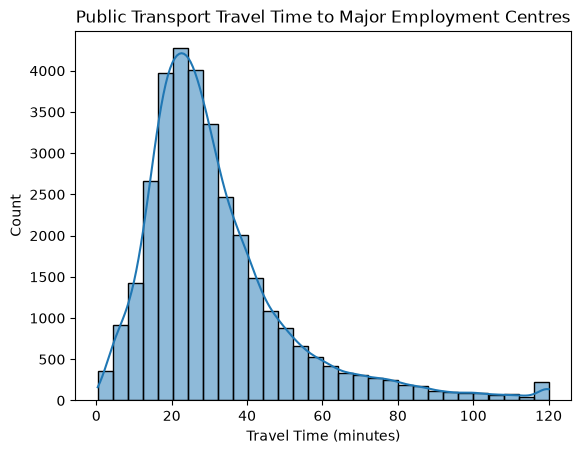

In [7]:
sns.histplot(df1["5000EmpPTt"], bins=30, kde=True)
plt.xlabel("Travel Time (minutes)")
plt.title("Public Transport Travel Time to Major Employment Centres")
plt.show()

The graph represents a right-Skewed distribution: The travel times are right-skewed, peaking sharply around 20-25 minutes, which represents the most typical public transport commute time to major employment centers. Core Commute Window: The vast majority of areas fall within a 15 to 40-minute travel time range.

Long-Tail Commutes: There is a gradual drop-off as travel time increases, with a thin long tail extending up to 120 minutes.

120-Minute Boundary Effect: A small uptick appears right at the 120-minute mark, likely reflecting data capping or a threshold limit for maximum recorded travel time.

## Regional Disparities in Public Transport Accessibility to Major Employment Centers

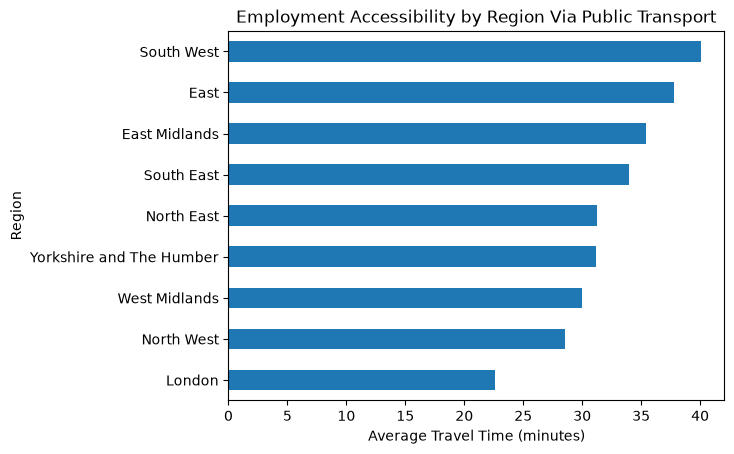

In [8]:
#Region-Wise Comparison
regional_access = (
    df1.groupby("Region")["5000EmpPTt"]
      .mean()
      .sort_values()
)

regional_access.plot(kind="barh")

plt.xlabel("Average Travel Time (minutes)")
plt.title("Employment Accessibility by Region Via Public Transport")
plt.show()

The above graph determines the Access to Employment Centres **via Public Transport** by Region. London has the highest accessibility, with the shortest average travel time of around 22.5 minutes while the South West has the lowest accessibility, requiring the longest average travel time at around 40 minutes. 
Keeping up with prior researched consensus, travel times generally increase as regions move further from major urban concentrations, with North West (28.5 mins) and West Midlands (30 mins) showing higher accessibility compared to the East (38 mins) and South West.

## Accessibility to Major Employment Centres
For relevance to project reuqirements, Employment centres with more than 5000 jobs available has been chosen

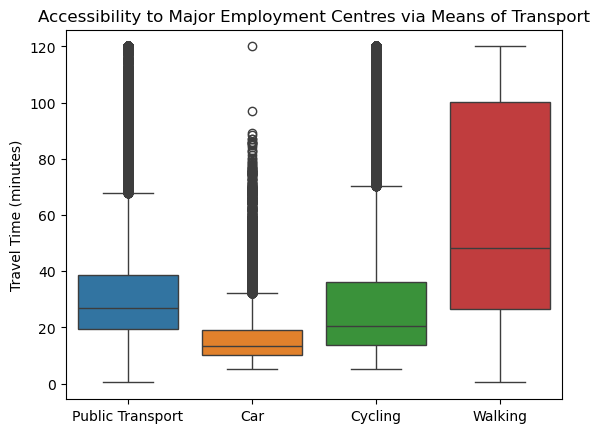

In [34]:
plot_df1 = df1[
    ["5000EmpPTt", "5000EmpCart", "5000EmpCyct", "5000EmpWalkt"]
].rename(columns={
    "5000EmpPTt": "Public Transport",
    "5000EmpCart": "Car",
    "5000EmpCyct": "Cycling",
    "5000EmpWalkt": "Walking"
})

sns.boxplot(data=plot_df1)

plt.ylabel("Travel Time (minutes)")
plt.title("Accessibility to Major Employment Centres via Means of Transport")
plt.show()

The graph above determines how different is accessibility for someone relying on public transport compared with someone using a car, cycle or by walking. Note: Only Employment Centres with more than 5000 people have been used to represent major employment hubs in England.
Most trips by car are fast and predictable. Cycling represents the second-fastest mode with a median travel time of roughly 20 minutes. 

Public Transport has median travel time of roughly 27minutes. Walking to stops, waiting for buses, and changing trains adds predictable extra time compared to driving or cycling.

# Feature Engineering

In [40]:
# 1. Public transport accessibility
df1["employment_pt_time"] = df1["5000EmpPTt"]

# 2. Car accessibility
df1["employment_car_time"] = df1["5000EmpCart"]

# 3. Disadvantage of using Public Transport compared with car
df1["employment_pt_car_gap"] = df1["5000EmpPTt"] - df1["5000EmpCart"]

# 4. Percentage of people with Public transport access within 30 minutes
df1["employment_pt_30min_pct"] = df1["5000EmpPT30pct"]

For the research purpose Variables associated with Employment centres with more than 5000 jobs available have been taken.

In [41]:
employment_features = df1[
    [
        "LSOA_code",
        "employment_pt_time",
        "employment_car_time",
        "employment_pt_car_gap",
        "employment_pt_30min_pct"
    ]
].copy()

employment_features.head(30)

,LSOA_code,employment_pt_time,employment_car_time,employment_pt_car_gap,employment_pt_30min_pct
0,E01000001,2.518604,5.706106,-3.187502,100.000000
1,E01000002,4.981653,6.435393,-1.453740,100.000000
2,E01000003,3.124925,5.984288,-2.859363,100.000000
3,E01000005,2.592090,6.282055,-3.689965,100.000000
4,E01000006,20.867462,11.775017,9.092445,100.000000
5,E01000007,18.063364,10.454008,7.609356,100.000000
6,E01000008,22.059455,11.264680,10.794775,100.000000
7,E01000009,16.545987,10.931068,5.614920,100.000000
8,E01000010,16.174186,10.059751,6.114436,100.000000
9,E01000011,15.459766,10.534524,4.925242,100.000000


The dataset was cleaned and transformed and then the selected features were then saved into a new dataset as shown below

In [43]:
employment_features.to_excel(
    "employment_features.xlsx",
    index=False
)